# AME 5152 — Applied Probability and Statistics
## Mid-Semester Examination: Python Solutions

This notebook contains simple, commented Python solutions for both questions from the uploaded question paper.

**Libraries used:** NumPy, SciPy, Pandas, and Matplotlib.

If needed, install the libraries with:
```python
pip install numpy scipy pandas matplotlib
```


# Question 1: Fraud Detection System

A fraud detection system processes transactions. Assume that 8% of transactions are fraudulent. It flags 85% of fraudulent transactions and incorrectly flags 10% of genuine transactions.

Write Python code to:

1. Simulate 10,000 independent transactions, storing the true fraud status and the system’s flag for each transaction.
2. Construct a table showing the number of fraudulent and genuine transactions that were flagged and not flagged.
3. Estimate the relevant probabilities from the simulation: the probability of a transaction being flagged, the probability of a flag given fraud, and the probability of fraud given a flag.
4. Calculate the theoretical probability of a flag using the law of total probability and the theoretical probability of fraud given a flag using Bayes’ rule. Compare these with the simulated estimates.


In [15]:
import numpy as np
import pandas as pd

# Given probabilities
p_fraud = 0.08
p_flag_fraud = 0.85
p_flag_genuine = 0.10

# Number of transactions to simulate
num = 10000

# Generate the true status of each transaction:
# True = Fraud, False = Genuine
fraud = np.random.rand(num) < p_fraud

# Set the probability of being flagged for each transaction
# Fraudulent transactions: 85%; genuine transactions: 10%
prob_flag = np.where(fraud, p_flag_fraud, p_flag_genuine)

# Simulate whether each transaction is flagged
# True = Flagged, False = Not flagged
flag = np.random.rand(num) < prob_flag

# Create a table of true status versus system flag
table = pd.crosstab(
    pd.Series(fraud, name="True Status"),
    pd.Series(flag, name="System Flag")
)

# Ensure both statuses and flag outcomes appear in the table
table = table.reindex(index=[False, True], columns=[False, True], fill_value=0)

# Give the rows and columns readable labels
table.index = ["Genuine", "Fraud"]
table.columns = ["Not Flagged", "Flagged"]

print("Transaction Table:")
display(table)


Transaction Table:


,Not Flagged,Flagged
Genuine,8351,894
Fraud,107,648


In [16]:
# Estimate probabilities from the simulated transactions

# Probability that a transaction is flagged
p_flag_sim = np.mean(flag)

# Probability that a fraudulent transaction is flagged
p_flag_given_fraud_sim = np.mean(flag[fraud])

# Probability that a flagged transaction is fraudulent
p_fraud_given_flag_sim = np.mean(fraud[flag])

print("Simulated P(Flag):", p_flag_sim)
print("Simulated P(Flag | Fraud):", p_flag_given_fraud_sim)
print("Simulated P(Fraud | Flag):", p_fraud_given_flag_sim)


Simulated P(Flag): 0.1542
Simulated P(Flag | Fraud): 0.8582781456953642
Simulated P(Fraud | Flag): 0.42023346303501946


In [17]:
# Calculate theoretical probabilities

# Law of total probability:
# P(Flag) = P(Flag | Fraud)P(Fraud)
#         + P(Flag | Genuine)P(Genuine)
p_flag_theory = (
    p_flag_fraud * p_fraud
    + p_flag_genuine * (1 - p_fraud)
)

# Bayes' rule:
# P(Fraud | Flag) = P(Flag | Fraud)P(Fraud) / P(Flag)
p_fraud_given_flag_theory = (
    p_flag_fraud * p_fraud / p_flag_theory
)

print("Theoretical P(Flag):", p_flag_theory)
print("Theoretical P(Fraud | Flag):", p_fraud_given_flag_theory)

# Compare simulated and theoretical estimates
comparison = pd.DataFrame({
    "Probability": ["P(Flag)", "P(Fraud | Flag)"],
    "Simulated": [p_flag_sim, p_fraud_given_flag_sim],
    "Theoretical": [p_flag_theory, p_fraud_given_flag_theory]
})

display(comparison.round(4))


Theoretical P(Flag): 0.16000000000000003
Theoretical P(Fraud | Flag): 0.42499999999999993


,Probability,Simulated,Theoretical
0,P(Flag),0.1542,0.160
1,P(Fraud | Flag),0.4202,0.425


Explanation
- np.random.rand(num) < p_fraud generates the true fraud status of each transaction.
- np.where() assigns a different flag probability to fraudulent and genuine transactions.
- pd.crosstab() creates a table of flagged and unflagged transactions.
- np.mean(flag) estimates the probability that a transaction is flagged.
- np.mean(fraud[flag]) estimates the probability that a flagged transaction is fraudulent.

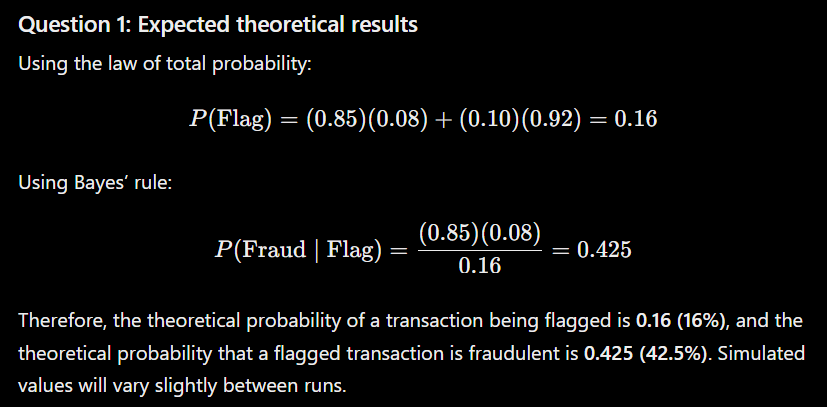

# Question 2: Server Request Failures — Binomial Distribution

A monitoring system checks 12 independent server requests during each minute. Each request has a 0.20 probability of failing. Let \(X\) be the number of failed requests in one minute.

Write Python code to:

1. Identify the distribution of \(X\), its parameters, and its possible values.
2. Simulate 20,000 minutes and calculate the empirical PMF for every possible value of \(X\).
3. Calculate the theoretical PMF and plot it alongside the empirical PMF.
4. Calculate the empirical and theoretical expectation and variance. Present the four values in a table.
5. Estimate \(P(X \geq 4)\) from the simulation and calculate it theoretically.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

# Given parameters
n = 12          # Requests checked per minute
p = 0.20        # Probability that each request fails
num = 20000     # Number of minutes to simulate

# X follows a Binomial distribution with parameters n and p
X = binom(n, p)

# Simulate the number of failed requests for each minute
# Each value in samples is between 0 and 12
samples = np.random.binomial(n=n, p=p, size=num)

# Possible values of X: 0, 1, 2, ..., 12
support = np.arange(n + 1)

print("Distribution: Binomial")
print("Number of trials (n):", n)
print("Probability of failure (p):", p)
print("Possible values of X:", support)


Distribution: Binomial
Number of trials (n): 12
Probability of failure (p): 0.2
Possible values of X: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]


In [5]:
# Calculate empirical and theoretical PMFs

# Empirical PMF: proportion of simulated minutes with exactly x failures
empirical_pmf = np.array([
    np.mean(samples == x) for x in support
])

# Theoretical PMF: probability calculated from the Binomial distribution
theoretical_pmf = X.pmf(support)

# Display both PMFs in a table
pmf_table = pd.DataFrame({
    "X (failed requests)": support,
    "Empirical PMF": empirical_pmf,
    "Theoretical PMF": theoretical_pmf
})

display(pmf_table.round(4))


,X (failed requests),Empirical PMF,Theoretical PMF
0,0,0.0690,0.0687
1,1,0.2030,0.2062
2,2,0.2876,0.2835
3,3,0.2318,0.2362
4,4,0.1320,0.1329
5,5,0.0562,0.0532
6,6,0.0159,0.0155
7,7,0.0038,0.0033
8,8,0.0006,0.0005
9,9,0.0000,0.0001


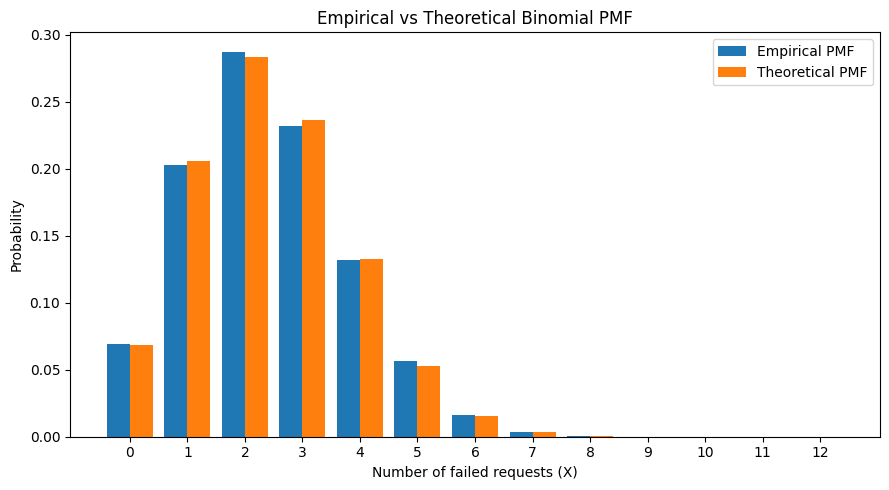

In [6]:
# Plot empirical and theoretical PMFs for comparison

plt.figure(figsize=(9, 5))

# Bars for the empirical probabilities
plt.bar(
    support - 0.2,
    empirical_pmf,
    width=0.4,
    label="Empirical PMF"
)

# Bars for the theoretical probabilities
plt.bar(
    support + 0.2,
    theoretical_pmf,
    width=0.4,
    label="Theoretical PMF"
)

plt.xlabel("Number of failed requests (X)")
plt.ylabel("Probability")
plt.title("Empirical vs Theoretical Binomial PMF")
plt.xticks(support)
plt.legend()
plt.tight_layout()
plt.show()


In [7]:
# Calculate empirical and theoretical expectation and variance

# Empirical values come from simulated data
empirical_mean = np.mean(samples)
empirical_var = np.var(samples)

# Theoretical values come from the Binomial distribution
theoretical_mean = X.mean()
theoretical_var = X.var()

# Present the four values in a table
stats_table = pd.DataFrame({
    "Measure": ["Expectation", "Variance"],
    "Empirical": [empirical_mean, empirical_var],
    "Theoretical": [theoretical_mean, theoretical_var]
})

display(stats_table.round(4))


,Measure,Empirical,Theoretical
0,Expectation,2.4104,2.40
1,Variance,1.9519,1.92


In [8]:
# Estimate P(X >= 4) from simulation

# Count the fraction of simulated minutes with 4 or more failures
p_ge_4_empirical = np.mean(samples >= 4)

# Calculate the theoretical probability using the complement:
# P(X >= 4) = 1 - P(X <= 3)
p_ge_4_theoretical = 1 - X.cdf(3)

print("Empirical P(X >= 4):", p_ge_4_empirical)
print("Theoretical P(X >= 4):", p_ge_4_theoretical)


Empirical P(X >= 4): 0.20865
Theoretical P(X >= 4): 0.2054310502400003


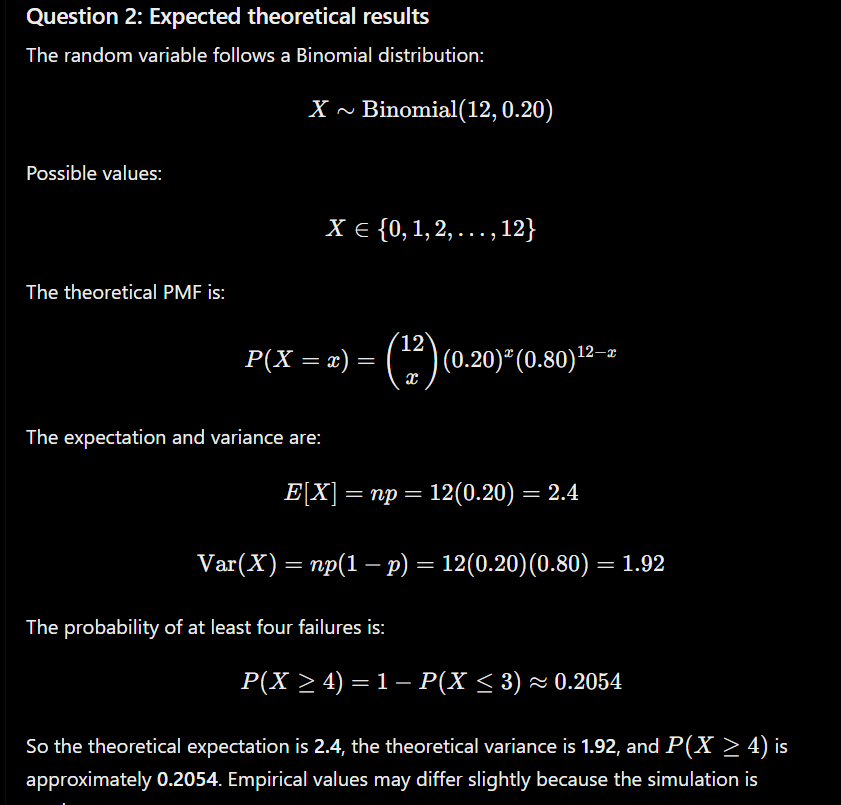